# TinyFault-FER — INT8 CNN + RTL Fault Injection

**Project:** Inference-aware RTL fault-injection analysis of an INT8 CNN classifier datapath for facial-expression recognition.

This notebook records the frozen TinyFault-FER experimental workflow:

1. Load the `abhilash88/fer2013-enhanced` dataset from Hugging Face.
2. Verify the provided splits and class balance.
3. Train a compact CNN for integer inference.
4. Convert the model to full-INT8 TFLite.
5. Evaluate FP32 and INT8 classification accuracy.
6. Extract deployed final-layer quantized tensors.
7. Reconstruct and verify integer MAC/accumulator arithmetic.
8. Generate and simulate the RTL datapath with Icarus Verilog.
9. Inject transient single-bit faults across all 32 accumulator positions.
10. Map the resulting accumulator corruptions to reconstructed final-layer class decisions and summarize vulnerability.

**Frozen dataset:** `abhilash88/fer2013-enhanced`  
**Classes:** Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral

Reported accuracy values refer to the dataset mirror's provided `train` / `validation` / `test` splits used in this notebook.


In [1]:

# Cell 1 — Install only the package Colab may not already have.
# No wget, Kaggle API, ZIP upload, or manual dataset download is used.
!pip -q install -U datasets

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 16.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:

# Cell 2 — Imports and reproducibility
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU(s):", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]



## 1. Direct FER2013 load

`load_dataset(...)` reads the public Hugging Face dataset directly into the Colab runtime/cache. There is no manual file handling.

This public mirror exposes three ready-to-use splits:

- `train`: 25,117 images
- `validation`: 5,380 images
- `test`: 5,390 images

The mirror exposes FER2013 pixels directly in Parquet-backed splits. We use the original 48×48 grayscale pixel values and the 7 emotion labels; the extra quality metadata is ignored.


In [3]:

# Cell 3 — Direct remote dataset load
DATASET_ID = "abhilash88/fer2013-enhanced"

raw = load_dataset(DATASET_ID)

print(raw)
print("\nAvailable splits:", list(raw.keys()))
for split in raw.keys():
    print(f"{split:>10}: {len(raw[split]):,} rows | columns={raw[split].column_names}")


README.md:   0%|          | 0.00/10.8k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  171MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 36.6MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25117 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5380 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5390 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 25117
    })
    validation: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 5380
    })
    test: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 5390
    })
})

Available splits: ['train', 'validation', 'test']
     train: 25,117 rows 

In [4]:

# Cell 4 — Sanity-check schema and one record
expected_splits = {"train", "validation", "test"}
missing = expected_splits - set(raw.keys())
assert not missing, f"Expected FER2013 splits missing: {missing}"

required_cols = {"emotion", "pixels"}
for split in expected_splits:
    assert required_cols.issubset(raw[split].column_names), (
        f"{split} missing required columns: {required_cols - set(raw[split].column_names)}"
    )

example = raw["train"][0]
print("Keys:", example.keys())
print("Label:", example["emotion"])

# This mirror provides both an image array and the original FER2013 pixel string.
pixel_count = len(example["pixels"].split())
print("Pixel count:", pixel_count)
assert pixel_count == 48 * 48


Keys: dict_keys(['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'])
Label: 6
Pixel count: 2304


In [5]:
# Cell 5 — Convert the original FER2013 pixel strings to compact NumPy arrays.
# The mirror contains extra metadata, but this project deliberately uses only
# the original 48x48 grayscale pixels and 7-class emotion label.

CLASS_NAMES = np.array([
    "Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"
])

def hf_split_to_numpy(ds):
    n = len(ds)
    x = np.empty((n, 48, 48, 1), dtype=np.uint8)
    y = np.asarray(ds["emotion"], dtype=np.int64)

    pixel_strings = ds["pixels"]
    for i, s in enumerate(pixel_strings):
        arr = np.fromstring(s, sep=" ", dtype=np.uint8)
        if arr.size != 2304:
            raise ValueError(f"Row {i}: expected 2304 pixels, got {arr.size}")
        x[i, :, :, 0] = arr.reshape(48, 48)

    return x, y

t0 = time.time()
x_train, y_train = hf_split_to_numpy(raw["train"])
x_val,   y_val   = hf_split_to_numpy(raw["validation"])
x_test,  y_test  = hf_split_to_numpy(raw["test"])

print(f"Conversion time: {time.time() - t0:.1f} s")
print("Train:", x_train.shape, y_train.shape, x_train.dtype)
print("Val:  ", x_val.shape,   y_val.shape)
print("Test: ", x_test.shape,  y_test.shape)

assert x_train.shape[1:] == (48, 48, 1)
assert set(np.unique(y_train)).issubset(set(range(7)))

Conversion time: 8.1 s
Train: (25117, 48, 48, 1) (25117,) uint8
Val:   (5380, 48, 48, 1) (5380,)
Test:  (5390, 48, 48, 1) (5390,)


,split,class_id,class_name,count,fraction
0,train,0,Angry,3467,0.138034
1,train,1,Disgust,382,0.015209
2,train,2,Fear,3584,0.142692
3,train,3,Happy,6292,0.250508
4,train,4,Sad,4253,0.169328
5,train,5,Surprise,2801,0.111518
6,train,6,Neutral,4338,0.172712
7,validation,0,Angry,742,0.137918
8,validation,1,Disgust,82,0.015242
9,validation,2,Fear,768,0.142751


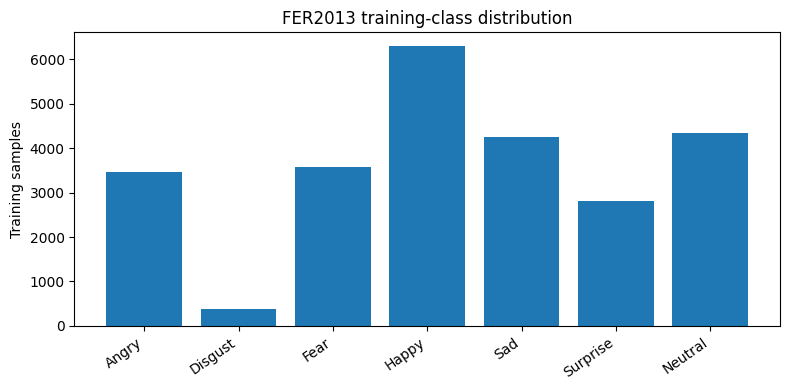

In [6]:

# Cell 6 — Class distribution
def class_count_table(y, split_name):
    counts = np.bincount(y, minlength=7)
    return pd.DataFrame({
        "split": split_name,
        "class_id": np.arange(7),
        "class_name": CLASS_NAMES,
        "count": counts,
        "fraction": counts / counts.sum()
    })

dist = pd.concat([
    class_count_table(y_train, "train"),
    class_count_table(y_val, "validation"),
    class_count_table(y_test, "test"),
], ignore_index=True)

display(dist)

train_counts = dist[dist["split"] == "train"]
plt.figure(figsize=(8, 4))
plt.bar(train_counts["class_name"], train_counts["count"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Training samples")
plt.title("FER2013 training-class distribution")
plt.tight_layout()
plt.show()


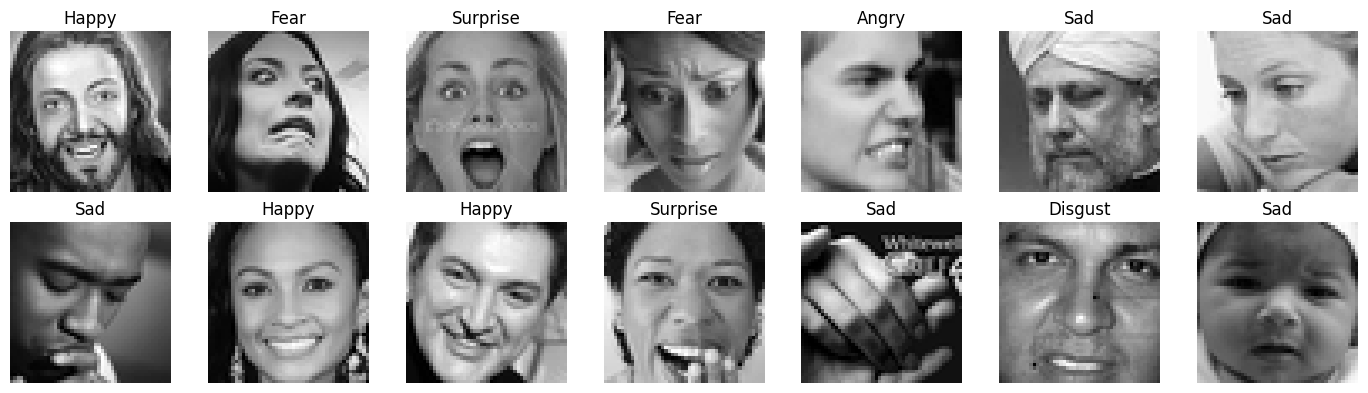

In [7]:

# Cell 7 — Visual sanity check
rng = np.random.default_rng(SEED)
idxs = rng.choice(len(x_train), size=14, replace=False)

fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for ax, idx in zip(axes.flat, idxs):
    ax.imshow(x_train[idx, :, :, 0], cmap="gray")
    ax.set_title(CLASS_NAMES[y_train[idx]])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. Compact CNN workload

A compact CNN is used as the quantized workload for the later RTL reliability experiment. The objective here is not state-of-the-art facial-expression recognition; the model only needs to provide a nontrivial deployed classifier whose integer arithmetic can be reconstructed and fault-tested.

Architecture:

`48×48×1 → Conv32×2 → Pool → Conv64×2 → Pool → Conv96 → GAP → Dense32 → Dense7`

Batch normalization is used during training and can be folded into convolution parameters during deployment conversion.


In [8]:
# Cell 8 — tf.data pipeline with light training-only augmentation
BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

def augment_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.image.random_flip_left_right(image)
    image = tf.image.resize_with_crop_or_pad(image, 52, 52)
    image = tf.image.random_crop(image, size=[48, 48, 1])
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, label

def cast_image(image, label):
    return tf.cast(image, tf.float32), label

def make_ds(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(min(len(x), 16000), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(augment_image, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(cast_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(x_train, y_train, training=True)
val_ds   = make_ds(x_val, y_val)
test_ds  = make_ds(x_test, y_test)

print("Training augmentation: horizontal flip + small translation crop + mild contrast")
print("Class weighting: OFF for this overall-accuracy baseline")

Training augmentation: horizontal flip + small translation crop + mild contrast
Class weighting: OFF for this overall-accuracy baseline


In [9]:
# Cell 9 — Build a compact but substantially stronger TFLite-friendly CNN
tf.keras.backend.clear_session()

inputs = tf.keras.Input(shape=(48, 48, 1), dtype=tf.float32, name="image")
x = tf.keras.layers.Rescaling(1.0 / 255.0, name="rescale")(inputs)

# Block 1
x = tf.keras.layers.Conv2D(32, 3, padding="same", use_bias=False, name="conv1a")(x)
x = tf.keras.layers.BatchNormalization(name="bn1a")(x)
x = tf.keras.layers.ReLU(name="relu1a")(x)
x = tf.keras.layers.Conv2D(32, 3, padding="same", use_bias=False, name="conv1b")(x)
x = tf.keras.layers.BatchNormalization(name="bn1b")(x)
x = tf.keras.layers.ReLU(name="relu1b")(x)
x = tf.keras.layers.MaxPooling2D(2, name="pool1")(x)
x = tf.keras.layers.Dropout(0.15, name="drop1")(x)

# Block 2
x = tf.keras.layers.Conv2D(64, 3, padding="same", use_bias=False, name="conv2a")(x)
x = tf.keras.layers.BatchNormalization(name="bn2a")(x)
x = tf.keras.layers.ReLU(name="relu2a")(x)
x = tf.keras.layers.Conv2D(64, 3, padding="same", use_bias=False, name="conv2b")(x)
x = tf.keras.layers.BatchNormalization(name="bn2b")(x)
x = tf.keras.layers.ReLU(name="relu2b")(x)
x = tf.keras.layers.MaxPooling2D(2, name="pool2")(x)
x = tf.keras.layers.Dropout(0.20, name="drop2")(x)

# Block 3
x = tf.keras.layers.Conv2D(96, 3, padding="same", use_bias=False, name="conv3")(x)
x = tf.keras.layers.BatchNormalization(name="bn3")(x)
x = tf.keras.layers.ReLU(name="relu3")(x)

x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
x = tf.keras.layers.Dense(32, activation="relu", name="dense32")(x)
x = tf.keras.layers.Dropout(0.25, name="drop3")(x)
outputs = tf.keras.layers.Dense(7, name="logits")(x)

model = tf.keras.Model(inputs, outputs, name="tinyfault_fer_cnn_v3")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

model.summary()
print("Total parameters:", model.count_params())

Model: "tinyfault_fer_cnn_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1a (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1a (BatchNormalization)       │ (None, 48, 48, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1a (ReLU)                   │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1b (Conv2D)                 │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1b (BatchNormalization)       │ (None, 48, 48, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1b (ReLU)                   │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2a (Conv2D)                 │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2a (BatchNormalization)       │ (None, 24, 24, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2a (ReLU)                   │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2b (Conv2D)                 │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2b (BatchNormalization)       │ (None, 24, 24, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2b (ReLU)                   │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 12, 12, 96)     │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 12, 12, 96)     │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 12, 12, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense32 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 7)              │           23

 Total params: 124,583 (486.65 KB)

 Trainable params: 124,007 (484.40 KB)

 Non-trainable params: 576 (2.25 KB)

Total parameters: 124583


In [10]:
# Cell 10 — Train
EPOCHS = 80

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=12,
        mode="max",
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/80
197/197 ━━━━━━━━━━━━━━━━━━━━ 31s 88ms/step - accuracy: 0.2773 - loss: 1.7636 - val_accuracy: 0.1727 - val_loss: 1.8564 - learning_rate: 0.0010
Epoch 2/80
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.3696 - loss: 1.5997 - val_accuracy: 0.1773 - val_loss: 2.0127 - learning_rate: 0.0010
Epoch 3/80
197/197 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.4272 - loss: 1.4882 - val_accuracy: 0.3270 - val_loss: 1.7348 - learning_rate: 0.0010
Epoch 4/80
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.4621 - loss: 1.4133 - val_accuracy: 0.4061 - val_loss: 1.6570 - learning_rate: 0.0010
Epoch 5/80
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.4804 - loss: 1.3632 - val_accuracy: 0.4896 - val_loss: 1.3471 - learning_rate: 0.0010
Epoch 6/80
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.5016 - loss: 1.3191 - val_accuracy: 0.4883 - val_loss: 1.3846 - learning_rate: 0.0010
Epoch 7/80
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.5132 - loss: 

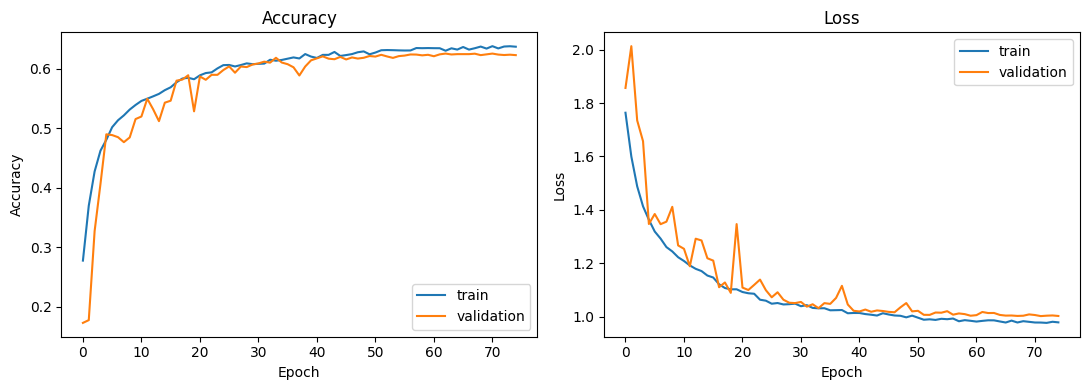

In [11]:

# Cell 11 — Learning curves
hist = pd.DataFrame(history.history)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(hist["accuracy"], label="train")
ax[0].plot(hist["val_accuracy"], label="validation")
ax[0].set_title("Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy")
ax[0].legend()

ax[1].plot(hist["loss"], label="train")
ax[1].plot(hist["val_loss"], label="validation")
ax[1].set_title("Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()

plt.tight_layout()
plt.show()


FP32 test loss:     1.0029
FP32 test accuracy: 62.4490%

              precision    recall  f1-score   support

       Angry     0.5516    0.5390    0.5452       744
     Disgust     0.0000    0.0000    0.0000        83
        Fear     0.4973    0.2406    0.3243       769
       Happy     0.8108    0.8866    0.8470      1349
         Sad     0.4995    0.5060    0.5027       913
    Surprise     0.6676    0.7687    0.7146       601
     Neutral     0.5505    0.7089    0.6197       931

    accuracy                         0.6245      5390
   macro avg     0.5110    0.5214    0.5077      5390
weighted avg     0.6042    0.6245    0.6054      5390



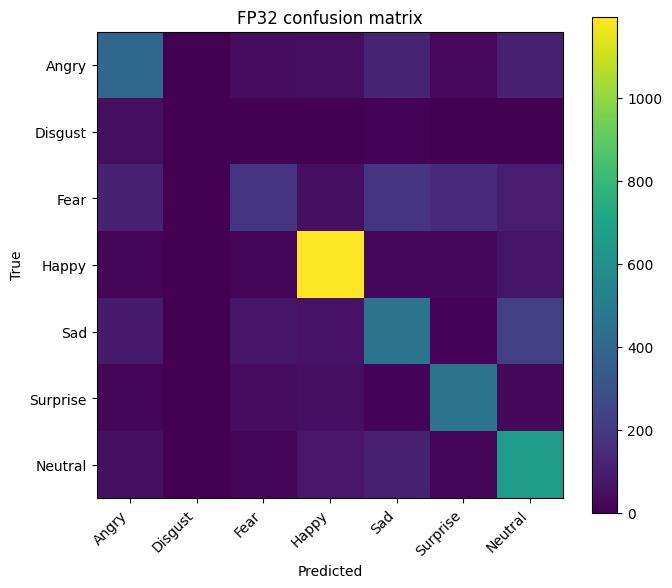

In [12]:

# Cell 12 — Locked clean test evaluation
fp32_loss, fp32_acc = model.evaluate(test_ds, verbose=0)
fp32_logits = model.predict(test_ds, verbose=0)
fp32_pred = np.argmax(fp32_logits, axis=1)

print(f"FP32 test loss:     {fp32_loss:.4f}")
print(f"FP32 test accuracy: {fp32_acc:.4%}")
print()
print(classification_report(
    y_test,
    fp32_pred,
    labels=np.arange(7),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_test, fp32_pred, labels=np.arange(7))
plt.figure(figsize=(7, 6))
plt.imshow(cm)
plt.title("FP32 confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(np.arange(7), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(np.arange(7), CLASS_NAMES)
plt.colorbar()
plt.tight_layout()
plt.show()


In [13]:

# Cell 13 — Save the FP32 model
ARTIFACT_DIR = Path("/content/tinyfault_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

fp32_path = ARTIFACT_DIR / "tinyfault_fer_v3_fp32.keras"
model.save(fp32_path)

print("Saved:", fp32_path)
print(f"Size: {fp32_path.stat().st_size / 1024:.1f} KiB")


Saved: /content/tinyfault_artifacts/tinyfault_fer_v3_fp32.keras
Size: 1557.0 KiB



## 3. Full-INT8 TFLite conversion

This is the deployment model used by the fault-injection stage below.

The representative set calibrates activation ranges. The converter is constrained to integer built-ins, and the float Keras input is quantized to a signed `int8` TFLite input; the output is also signed `int8`.


In [14]:

# Cell 14 — Representative calibration set
# Deterministic subset; no test samples are used for calibration.
REP_SAMPLES = 512
rep_idx = np.random.default_rng(SEED).choice(
    len(x_train), size=REP_SAMPLES, replace=False
)
x_rep = x_train[rep_idx]

def representative_dataset():
    for i in range(len(x_rep)):
        # Converter calibration expects the model's logical input values.
        yield [x_rep[i:i+1].astype(np.float32)]


In [15]:

# Cell 15 — Convert to full INT8 TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_int8 = converter.convert()

int8_path = ARTIFACT_DIR / "tinyfault_fer_v3_int8.tflite"
int8_path.write_bytes(tflite_int8)

print("Saved:", int8_path)
print(f"INT8 TFLite size: {int8_path.stat().st_size / 1024:.1f} KiB")


Saved artifact at '/tmp/tmp3wzm1ptw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 48, 48, 1), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  137044018472208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137044366945232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137044366944848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137044018470096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137044018468368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137042874158544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137042874156240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137042874156816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137042874156048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137042874158928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137042874158352: Tensor

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved: /content/tinyfault_artifacts/tinyfault_fer_v3_int8.tflite
INT8 TFLite size: 135.9 KiB


In [16]:

# Cell 16 — Inspect quantized input/output
interpreter = tf.lite.Interpreter(
    model_content=tflite_int8,
    experimental_preserve_all_tensors=True
)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("INPUT:")
for d in input_details:
    print({
        "name": d["name"],
        "shape": d["shape"].tolist(),
        "dtype": str(d["dtype"]),
        "quantization": d["quantization"],
    })

print("\nOUTPUT:")
for d in output_details:
    print({
        "name": d["name"],
        "shape": d["shape"].tolist(),
        "dtype": str(d["dtype"]),
        "quantization": d["quantization"],
    })

assert input_details[0]["dtype"] == np.int8
assert output_details[0]["dtype"] == np.int8


INPUT:
{'name': 'serving_default_image:0', 'shape': [1, 48, 48, 1], 'dtype': "<class 'numpy.int8'>", 'quantization': (1.0, -128)}

OUTPUT:
{'name': 'StatefulPartitionedCall_1:0', 'shape': [1, 7], 'dtype': "<class 'numpy.int8'>", 'quantization': (0.07783900201320648, -1)}


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:465: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(


In [17]:

# Cell 17 — Helper functions for exact TFLite I/O quantization
input_index = input_details[0]["index"]
output_index = output_details[0]["index"]

in_scale, in_zero = input_details[0]["quantization"]
out_scale, out_zero = output_details[0]["quantization"]

assert in_scale > 0 and out_scale > 0

def quantize_to_int8(x, scale, zero_point):
    q = np.round(x / scale + zero_point)
    return np.clip(q, -128, 127).astype(np.int8)

def dequantize_from_int8(q, scale, zero_point):
    return (q.astype(np.float32) - zero_point) * scale

def tflite_predict_one(image_uint8):
    # Logical model input is uint8 pixel intensity. The TFLite tensor itself is int8.
    q_in = quantize_to_int8(
        image_uint8.astype(np.float32)[None, ...],
        in_scale,
        in_zero
    )
    interpreter.set_tensor(input_index, q_in)
    interpreter.invoke()
    q_out = interpreter.get_tensor(output_index)
    logits = dequantize_from_int8(q_out, out_scale, out_zero)
    return logits[0]


In [18]:

# Cell 18 — Evaluate INT8 model on the entire test split
int8_pred = np.empty(len(x_test), dtype=np.int64)
int8_logits = np.empty((len(x_test), 7), dtype=np.float32)

for i in range(len(x_test)):
    logits = tflite_predict_one(x_test[i])
    int8_logits[i] = logits
    int8_pred[i] = int(np.argmax(logits))

int8_acc = float(np.mean(int8_pred == y_test))
agreement = float(np.mean(int8_pred == fp32_pred))

print(f"FP32 accuracy:      {fp32_acc:.4%}")
print(f"INT8 accuracy:      {int8_acc:.4%}")
print(f"Accuracy delta:     {(int8_acc - fp32_acc)*100:+.3f} percentage points")
print(f"FP32/INT8 agreement:{agreement:.4%}")


FP32 accuracy:      62.4490%
INT8 accuracy:      62.5417%
Accuracy delta:     +0.093 percentage points
FP32/INT8 agreement:98.4416%


,model,test_accuracy,file_kib
0,FP32 Keras,0.624490,1557.038086
1,Full INT8 TFLite,0.625417,135.875000


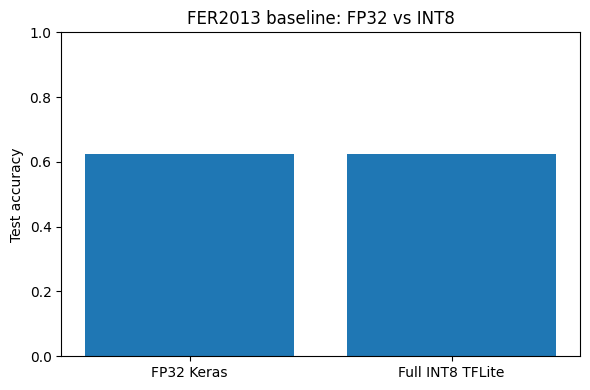

In [19]:

# Cell 19 — Baseline comparison plot
comparison = pd.DataFrame({
    "model": ["FP32 Keras", "Full INT8 TFLite"],
    "test_accuracy": [fp32_acc, int8_acc],
    "file_kib": [
        fp32_path.stat().st_size / 1024,
        int8_path.stat().st_size / 1024
    ]
})

display(comparison)

plt.figure(figsize=(6, 4))
plt.bar(comparison["model"], comparison["test_accuracy"])
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("FER2013 baseline: FP32 vs INT8")
plt.tight_layout()
plt.show()


## 4. Freeze the fault-campaign seed set

For the hardware study, only samples that the **INT8 model classifies correctly** are selected. This prevents ordinary model errors from being counted as hardware-fault effects.

The campaign uses 100 such test samples selected without replacement. These frozen samples are used by the RTL stage below.


In [20]:

# Cell 20 — Freeze 100 correctly classified INT8 test samples
correct_idx = np.flatnonzero(int8_pred == y_test)

N_FAULT_SEEDS = min(100, len(correct_idx))
rng = np.random.default_rng(SEED)
fault_seed_idx = np.sort(rng.choice(correct_idx, size=N_FAULT_SEEDS, replace=False))

seed_path = ARTIFACT_DIR / "fault_seed_samples.npz"
np.savez_compressed(
    seed_path,
    indices=fault_seed_idx,
    images=x_test[fault_seed_idx],
    labels=y_test[fault_seed_idx],
    fp32_pred=fp32_pred[fault_seed_idx],
    int8_pred=int8_pred[fault_seed_idx],
    int8_logits=int8_logits[fault_seed_idx],
)

print("Correctly classified INT8 test samples:", len(correct_idx))
print("Exported seeds:", N_FAULT_SEEDS)
print("Saved:", seed_path)


Correctly classified INT8 test samples: 3371
Exported seeds: 100
Saved: /content/tinyfault_artifacts/fault_seed_samples.npz


## 5. Inspect deployed INT8 tensors

Before RTL simulation, the notebook inspects the deployed TFLite tensor inventory and identifies the tensors associated with the final `FULLY_CONNECTED` classifier.

The RTL stage below targets that final 32-input, 7-output classifier datapath. Quantized activations, weights, biases, scales, and zero-points are extracted from the deployed TFLite model and used to reconstruct its integer accumulator arithmetic.


In [21]:

# Cell 21 — Quantized tensor inventory
tensor_details = interpreter.get_tensor_details()

rows = []
for d in tensor_details:
    qp = d["quantization_parameters"]
    scales = qp.get("scales", np.array([]))
    rows.append({
        "index": d["index"],
        "name": d["name"],
        "shape": tuple(d["shape"].tolist()),
        "dtype": np.dtype(d["dtype"]).name,
        "n_scales": int(len(scales)),
        "scale_preview": float(scales[0]) if len(scales) else np.nan,
    })

tensor_df = pd.DataFrame(rows)

# Show only integer tensors, with likely convolution tensors first.
int_tensor_df = tensor_df[tensor_df["dtype"].isin(["int8", "int16", "int32"])].copy()
display(int_tensor_df.head(80))


,index,name,shape,dtype,n_scales,scale_preview
0,0,serving_default_image:0,"(1, 48, 48, 1)",int8,1,1.000000
1,1,tinyfault_fer_cnn_v3_1/gap_1/Mean/reduction_in...,"(2,)",int32,0,NaN
2,2,tinyfault_fer_cnn_v3_1/logits_1/BiasAdd,"(7,)",int32,7,0.000122
3,3,tinyfault_fer_cnn_v3_1/logits_1/MatMul,"(7, 32)",int8,7,0.008109
4,4,tinyfault_fer_cnn_v3_1/dense32_1/Relu;tinyfaul...,"(32,)",int32,32,0.000023
5,5,tinyfault_fer_cnn_v3_1/dense32_1/MatMul,"(32, 96)",int8,32,0.003335
6,6,tinyfault_fer_cnn_v3_1/relu3_1/Relu;tinyfault_...,"(96,)",int32,96,0.000065
7,7,tinyfault_fer_cnn_v3_1/conv3_1/convolution,"(96, 3, 3, 64)",int8,96,0.002658
8,8,tinyfault_fer_cnn_v3_1/relu2b_1/Relu;tinyfault...,"(64,)",int32,64,0.000061
9,9,tinyfault_fer_cnn_v3_1/conv2b_1/convolution,"(64, 3, 3, 64)",int8,64,0.001556


In [22]:

# Cell 22 — Run one seed and preserve intermediate tensors
seed_i = int(fault_seed_idx[0])
q_in = quantize_to_int8(
    x_test[seed_i].astype(np.float32)[None, ...],
    in_scale,
    in_zero
)
interpreter.set_tensor(input_index, q_in)
interpreter.invoke()

print("Seed test index:", seed_i)
print("True class:", CLASS_NAMES[y_test[seed_i]])
print("INT8 prediction:", CLASS_NAMES[int8_pred[seed_i]])

# Find tensors containing conv-related names; exact names can vary across TF versions.
conv_candidates = tensor_df[
    tensor_df["name"].str.contains("conv", case=False, regex=False)
]
display(conv_candidates)


Seed test index: 243
True class: Happy
INT8 prediction: Happy


,index,name,shape,dtype,n_scales,scale_preview
6,6,tinyfault_fer_cnn_v3_1/relu3_1/Relu;tinyfault_...,"(96,)",int32,96,0.000065
7,7,tinyfault_fer_cnn_v3_1/conv3_1/convolution,"(96, 3, 3, 64)",int8,96,0.002658
8,8,tinyfault_fer_cnn_v3_1/relu2b_1/Relu;tinyfault...,"(64,)",int32,64,0.000061
9,9,tinyfault_fer_cnn_v3_1/conv2b_1/convolution,"(64, 3, 3, 64)",int8,64,0.001556
10,10,tinyfault_fer_cnn_v3_1/relu2a_1/Relu;tinyfault...,"(64,)",int32,64,0.000037
11,11,tinyfault_fer_cnn_v3_1/conv2a_1/convolution,"(64, 3, 3, 32)",int8,64,0.001174
12,12,tinyfault_fer_cnn_v3_1/relu1b_1/Relu;tinyfault...,"(32,)",int32,32,0.000050
13,13,tinyfault_fer_cnn_v3_1/conv1b_1/convolution,"(32, 3, 3, 32)",int8,32,0.001480
14,14,tinyfault_fer_cnn_v3_1/relu1a_1/Relu;tinyfault...,"(32,)",int32,32,0.000131
15,15,tinyfault_fer_cnn_v3_1/relu1a_1/Relu;tinyfault...,"(32, 3, 3, 1)",int8,32,0.000131


## 6. Baseline checks before RTL

The following summary records the dataset sizes, FP32 and INT8 accuracy, INT8/FP32 prediction agreement, model sizes, TFLite input/output dtypes, and the number of correctly classified INT8 samples available for the fault campaign.

These values document the frozen software baseline used by the RTL stage.


In [23]:

# Cell 23 — Compact experiment summary
summary = {
    "dataset": DATASET_ID,
    "train_n": int(len(x_train)),
    "validation_n": int(len(x_val)),
    "test_n": int(len(x_test)),
    "parameters": int(model.count_params()),
    "fp32_test_accuracy": float(fp32_acc),
    "int8_test_accuracy": float(int8_acc),
    "accuracy_delta_pp": float((int8_acc - fp32_acc) * 100.0),
    "fp32_int8_prediction_agreement": float(agreement),
    "fp32_file_kib": float(fp32_path.stat().st_size / 1024),
    "int8_file_kib": float(int8_path.stat().st_size / 1024),
    "fault_seed_count": int(N_FAULT_SEEDS),
    "int8_input_quantization": {
        "scale": float(in_scale),
        "zero_point": int(in_zero)
    },
    "int8_output_quantization": {
        "scale": float(out_scale),
        "zero_point": int(out_zero)
    },
}

display(pd.Series(summary, name="value"))
print("\nRAW SUMMARY DICT:")
print(summary)


,value
dataset,abhilash88/fer2013-enhanced
train_n,25117
validation_n,5380
test_n,5390
parameters,124583
fp32_test_accuracy,0.62449
int8_test_accuracy,0.625417
accuracy_delta_pp,0.092766
fp32_int8_prediction_agreement,0.984416
fp32_file_kib,1557.038086



RAW SUMMARY DICT:
{'dataset': 'abhilash88/fer2013-enhanced', 'train_n': 25117, 'validation_n': 5380, 'test_n': 5390, 'parameters': 124583, 'fp32_test_accuracy': 0.6244897842407227, 'int8_test_accuracy': 0.625417439703154, 'accuracy_delta_pp': 0.09276554624313427, 'fp32_int8_prediction_agreement': 0.9844155844155844, 'fp32_file_kib': 1557.0380859375, 'int8_file_kib': 135.875, 'fault_seed_count': 100, 'int8_input_quantization': {'scale': 1.0, 'zero_point': -128}, 'int8_output_quantization': {'scale': 0.07783900201320648, 'zero_point': -1}}


# RTL Stage — Final-Layer INT8 Accumulator Fault Injection

The classifier baseline is frozen at this point; the RTL stage does **not** modify or retrain the CNN.

### Hardware target

The fault-analysis target is the deployed INT8 TFLite model's final `FULLY_CONNECTED` layer:

- 32 quantized input features
- 7 output neurons
- signed INT8 weights and activations
- signed 32-bit accumulation

The notebook:

1. extracts the deployed TFLite operands;
2. folds asymmetric activation zero-point correction into the bias so the RTL datapath remains an INT8 × INT8 MAC;
3. verifies the Verilog MAC against the Python integer reference;
4. captures final-layer activation vectors for the frozen inference seeds;
5. injects one transient bit flip into each of the 32 bits of each completed output-neuron accumulator;
6. maps each corrupted accumulator to reconstructed final-layer class scores and records whether the argmax changes.

The RTL implementation therefore represents the **final classifier MAC/accumulator datapath**, not the complete CNN.


In [25]:

# Cell 26 — Install Icarus Verilog
!apt-get -qq update
!apt-get -qq install -y iverilog

import subprocess
from pathlib import Path

print(subprocess.check_output(["iverilog", "-V"], text=True, stderr=subprocess.STDOUT).splitlines()[0])


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu/dists/noble/InRelease  503  Service Unavailable [IP: 185.125.189.188 443]
W: Some index files failed to download. They have been ignored, or old ones used instead.
Selecting previously unselected package iverilog.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../iverilog_12.0-2build2_amd64.deb ...
Unpacking iverilog (12.0-2build2) ...
Setting up iverilog (12.0-2build2) ...
Processing triggers for man-db (2.12.0-4build2) ...
Icarus Verilog version 12.0 (stable) ()


In [26]:

# Cell 27 — Locate the final INT8 FULLY_CONNECTED operator in TFLite

# The interpreter was created earlier with experimental_preserve_all_tensors=True.
ops = interpreter._get_ops_details()
fc_ops = [op for op in ops if op["op_name"] == "FULLY_CONNECTED"]

assert fc_ops, "No FULLY_CONNECTED operator found in the TFLite model."
final_fc = fc_ops[-1]

print("Number of FULLY_CONNECTED ops:", len(fc_ops))
print("Final FULLY_CONNECTED op:")
print(final_fc)

fc_input_indices = [int(i) for i in final_fc["inputs"] if int(i) >= 0]
fc_output_indices = [int(i) for i in final_fc["outputs"] if int(i) >= 0]

assert len(fc_input_indices) >= 2, "Unexpected FULLY_CONNECTED input structure."

ACT_IDX = fc_input_indices[0]
WEIGHT_IDX = fc_input_indices[1]
BIAS_IDX = fc_input_indices[2] if len(fc_input_indices) >= 3 else None
FC_OUT_IDX = fc_output_indices[0]

td_by_index = {int(d["index"]): d for d in interpreter.get_tensor_details()}

for label, idx in [
    ("activation", ACT_IDX),
    ("weights", WEIGHT_IDX),
    ("bias", BIAS_IDX),
    ("output", FC_OUT_IDX),
]:
    if idx is None:
        print(label, ": None")
        continue
    d = td_by_index[idx]
    print(
        f"{label:>10} idx={idx:>3} "
        f"shape={tuple(d['shape'].tolist())} "
        f"dtype={np.dtype(d['dtype']).name} "
        f"name={d['name']}"
    )


Number of FULLY_CONNECTED ops: 2
Final FULLY_CONNECTED op:
{'index': 9, 'op_name': 'FULLY_CONNECTED', 'inputs': array([24,  3,  2], dtype=int32), 'outputs': array([25], dtype=int32), 'operand_types': [<class 'numpy.int8'>, <class 'numpy.int8'>, <class 'numpy.int32'>], 'result_types': [<class 'numpy.int8'>]}
activation idx= 24 shape=(1, 32) dtype=int8 name=tinyfault_fer_cnn_v3_1/dense32_1/MatMul;tinyfault_fer_cnn_v3_1/dense32_1/Relu;tinyfault_fer_cnn_v3_1/dense32_1/BiasAdd
   weights idx=  3 shape=(7, 32) dtype=int8 name=tinyfault_fer_cnn_v3_1/logits_1/MatMul
      bias idx=  2 shape=(7,) dtype=int32 name=tinyfault_fer_cnn_v3_1/logits_1/BiasAdd
    output idx= 25 shape=(1, 7) dtype=int8 name=StatefulPartitionedCall_1:0


In [27]:

# Cell 28 — Extract exact quantized weights, bias, scales and zero-points

W_Q = interpreter.get_tensor(WEIGHT_IDX).astype(np.int8)
assert W_Q.ndim == 2, f"Expected 2D FC weights, got {W_Q.shape}"

N_CLASSES, N_FEATURES = W_Q.shape

if BIAS_IDX is None:
    B_Q = np.zeros(N_CLASSES, dtype=np.int32)
else:
    B_Q = interpreter.get_tensor(BIAS_IDX).reshape(-1).astype(np.int32)

act_detail = td_by_index[ACT_IDX]
weight_detail = td_by_index[WEIGHT_IDX]

act_qp = act_detail["quantization_parameters"]
weight_qp = weight_detail["quantization_parameters"]

ACT_SCALE = float(act_qp["scales"][0])
ACT_ZP = int(act_qp["zero_points"][0])

weight_scales = np.asarray(weight_qp["scales"], dtype=np.float64)
weight_zps = np.asarray(weight_qp["zero_points"], dtype=np.int64)

if weight_scales.size == 1:
    WEIGHT_SCALES = np.repeat(weight_scales, N_CLASSES)
else:
    assert weight_scales.size == N_CLASSES, (
        f"Expected 1 or {N_CLASSES} weight scales, got {weight_scales.size}"
    )
    WEIGHT_SCALES = weight_scales

if weight_zps.size == 1:
    WEIGHT_ZPS = np.repeat(weight_zps, N_CLASSES)
else:
    assert weight_zps.size == N_CLASSES
    WEIGHT_ZPS = weight_zps

# Standard full-int8 TFLite FC weights should be symmetric.
assert np.all(WEIGHT_ZPS == 0), (
    "This RTL formulation assumes symmetric int8 weights (weight zero-point = 0). "
    f"Observed: {np.unique(WEIGHT_ZPS)}"
)

assert B_Q.shape == (N_CLASSES,)
assert N_CLASSES == 7, f"Expected 7 FER classes, found {N_CLASSES}"

# Fold activation zero-point correction into the bias:
# sum((x - zp_x) * w) + bias
# = sum(x*w) + [bias - zp_x * sum(w)]  when zp_w = 0.
B_RTL = (
    B_Q.astype(np.int64)
    - ACT_ZP * W_Q.astype(np.int64).sum(axis=1)
)

assert np.all(B_RTL >= np.iinfo(np.int32).min)
assert np.all(B_RTL <= np.iinfo(np.int32).max)
B_RTL = B_RTL.astype(np.int32)

ACC_SCALES = ACT_SCALE * WEIGHT_SCALES

print("Final layer:", N_FEATURES, "inputs ->", N_CLASSES, "classes")
print("Activation scale:", ACT_SCALE)
print("Activation zero-point:", ACT_ZP)
print("Weight zero-points:", np.unique(WEIGHT_ZPS))
print("Weight-scale range:", float(WEIGHT_SCALES.min()), "to", float(WEIGHT_SCALES.max()))
print("Adjusted RTL bias range:", int(B_RTL.min()), "to", int(B_RTL.max()))


Final layer: 32 inputs -> 7 classes
Activation scale: 0.015099885873496532
Activation zero-point: -128
Weight zero-points: [0]
Weight-scale range: 0.005706930998712778 to 0.01016418356448412
Adjusted RTL bias range: -94531 to 5579


In [28]:

# Cell 29 — Capture actual final-layer INT8 activations for the 100 frozen seeds

assert len(fault_seed_idx) == N_FAULT_SEEDS
seed_activations = np.empty((N_FAULT_SEEDS, N_FEATURES), dtype=np.int8)
seed_tflite_pred = np.empty(N_FAULT_SEEDS, dtype=np.int64)

for row, test_idx in enumerate(fault_seed_idx):
    q_in = quantize_to_int8(
        x_test[int(test_idx)].astype(np.float32)[None, ...],
        in_scale,
        in_zero,
    )
    interpreter.set_tensor(input_index, q_in)
    interpreter.invoke()

    a = interpreter.get_tensor(ACT_IDX).reshape(-1)
    assert a.size == N_FEATURES
    assert a.dtype == np.int8
    seed_activations[row] = a

    out_q = interpreter.get_tensor(output_index)
    out_float = dequantize_from_int8(out_q, out_scale, out_zero)
    seed_tflite_pred[row] = int(np.argmax(out_float[0]))

print("Captured activation matrix:", seed_activations.shape, seed_activations.dtype)
print("Seed labels correct under TFLite:", np.mean(seed_tflite_pred == y_test[fault_seed_idx]))


Captured activation matrix: (100, 32) int8
Seed labels correct under TFLite: 1.0


In [29]:
# Cell 30 — Python reference accumulator reconstruction
# Keep only seeds whose reconstructed final-layer decision exactly matches TFLite.

def python_clean_accumulators(x_q):
    x = x_q.astype(np.int64)
    w = W_Q.astype(np.int64)
    return B_RTL.astype(np.int64) + (w * x[None, :]).sum(axis=1)

clean_acc_py = np.stack(
    [python_clean_accumulators(x) for x in seed_activations],
    axis=0
)

# Convert accumulator integers to the pre-output-quantization real domain.
clean_logits_from_acc = (
    clean_acc_py.astype(np.float64) * ACC_SCALES[None, :]
)
clean_pred_from_acc = np.argmax(clean_logits_from_acc, axis=1)

match_mask = (clean_pred_from_acc == seed_tflite_pred)

original_n = len(match_mask)
matched_n = int(match_mask.sum())

print(
    "Accumulator reconstruction ↔ TFLite prediction agreement:",
    f"{matched_n / original_n:.2%}"
)
print(
    f"Keeping {matched_n}/{original_n} seeds with exact clean-decision agreement."
)

# For RTL fault injection, use only seeds whose clean reconstructed decision
# agrees with the actual deployed TFLite model.
fault_seed_idx = fault_seed_idx[match_mask]
seed_activations = seed_activations[match_mask]
seed_tflite_pred = seed_tflite_pred[match_mask]
clean_acc_py = clean_acc_py[match_mask]
clean_logits_from_acc = clean_logits_from_acc[match_mask]
clean_pred_from_acc = clean_pred_from_acc[match_mask]

N_FAULT_SEEDS = len(fault_seed_idx)

reconstruction_agreement = float(
    np.mean(clean_pred_from_acc == seed_tflite_pred)
)

assert reconstruction_agreement == 1.0

print(
    "RTL campaign clean-baseline agreement after filtering:",
    f"{reconstruction_agreement:.2%}"
)
print("Final RTL seed count:", N_FAULT_SEEDS)

Accumulator reconstruction ↔ TFLite prediction agreement: 100.00%
Keeping 100/100 seeds with exact clean-decision agreement.
RTL campaign clean-baseline agreement after filtering: 100.00%
Final RTL seed count: 100


In [30]:

# Cell 31 — Create RTL source and campaign memory files

RTL_DIR = Path("/content/tinyfault_rtl")
RTL_DIR.mkdir(parents=True, exist_ok=True)

mac_sv = r'''
module int8_mac_accum (
    input  logic signed [7:0]  x,
    input  logic signed [7:0]  w,
    input  logic signed [31:0] acc_in,
    output logic signed [31:0] acc_out
);
    logic signed [15:0] product;

    always_comb begin
        product = x * w;
        acc_out = acc_in + {{16{product[15]}}, product};
    end
endmodule


module bitflip32 (
    input  logic signed [31:0] din,
    input  logic        [4:0]  bit_index,
    output logic signed [31:0] dout
);
    always_comb begin
        dout = din ^ (32'h00000001 << bit_index);
    end
endmodule
'''

tb_sv = f'''
module tb_fault_campaign;

    localparam integer N_SAMPLES  = {N_FAULT_SEEDS};
    localparam integer N_CLASSES  = {N_CLASSES};
    localparam integer N_FEATURES = {N_FEATURES};

    logic signed [7:0]  activations [0:N_SAMPLES*N_FEATURES-1];
    logic signed [7:0]  weights     [0:N_CLASSES*N_FEATURES-1];
    logic signed [31:0] biases      [0:N_CLASSES-1];

    logic signed [7:0]  x;
    logic signed [7:0]  w;
    logic signed [31:0] acc_in;
    logic signed [31:0] acc_out;

    logic signed [31:0] clean_acc;
    logic signed [31:0] faulted_acc;
    logic        [4:0]  bit_index;

    integer sample_i;
    integer neuron_i;
    integer feature_i;
    integer bit_i;
    integer fout;

    int8_mac_accum dut_mac (
        .x(x),
        .w(w),
        .acc_in(acc_in),
        .acc_out(acc_out)
    );

    bitflip32 dut_fault (
        .din(clean_acc),
        .bit_index(bit_index),
        .dout(faulted_acc)
    );

    initial begin
        $readmemh("activations.mem", activations);
        $readmemh("weights.mem", weights);
        $readmemh("biases.mem", biases);

        fout = $fopen("rtl_faults.csv", "w");
        $fwrite(fout, "sample,neuron,bit,clean_acc,faulted_acc\\n");

        for (sample_i = 0; sample_i < N_SAMPLES; sample_i = sample_i + 1) begin
            for (neuron_i = 0; neuron_i < N_CLASSES; neuron_i = neuron_i + 1) begin
                clean_acc = biases[neuron_i];

                for (feature_i = 0; feature_i < N_FEATURES; feature_i = feature_i + 1) begin
                    x = activations[sample_i*N_FEATURES + feature_i];
                    w = weights[neuron_i*N_FEATURES + feature_i];
                    acc_in = clean_acc;
                    #1;
                    clean_acc = acc_out;
                end

                for (bit_i = 0; bit_i < 32; bit_i = bit_i + 1) begin
                    bit_index = bit_i[4:0];
                    #1;
                    $fwrite(
                        fout,
                        "%0d,%0d,%0d,%0d,%0d\\n",
                        sample_i,
                        neuron_i,
                        bit_i,
                        clean_acc,
                        faulted_acc
                    );
                end
            end
        end

        $fclose(fout);
        $display("FAULT_CAMPAIGN_COMPLETE");
        $finish;
    end
endmodule
'''

(RTL_DIR / "int8_mac_accum.sv").write_text(mac_sv)
(RTL_DIR / "tb_fault_campaign.sv").write_text(tb_sv)

def write_hex_mem(path, values, bits):
    mask = (1 << bits) - 1
    width = bits // 4
    with open(path, "w") as f:
        for v in np.asarray(values).reshape(-1):
            f.write(f"{int(v) & mask:0{width}x}\n")

write_hex_mem(RTL_DIR / "activations.mem", seed_activations, 8)
write_hex_mem(RTL_DIR / "weights.mem", W_Q, 8)
write_hex_mem(RTL_DIR / "biases.mem", B_RTL, 32)

print((RTL_DIR / "int8_mac_accum.sv").read_text())
print("RTL directory:", RTL_DIR)
print("Activation values:", seed_activations.size)
print("Weight values:", W_Q.size)



module int8_mac_accum (
    input  logic signed [7:0]  x,
    input  logic signed [7:0]  w,
    input  logic signed [31:0] acc_in,
    output logic signed [31:0] acc_out
);
    logic signed [15:0] product;

    always_comb begin
        product = x * w;
        acc_out = acc_in + {{16{product[15]}}, product};
    end
endmodule


module bitflip32 (
    input  logic signed [31:0] din,
    input  logic        [4:0]  bit_index,
    output logic signed [31:0] dout
);
    always_comb begin
        dout = din ^ (32'h00000001 << bit_index);
    end
endmodule

RTL directory: /content/tinyfault_rtl
Activation values: 3200
Weight values: 224


In [31]:

# Cell 32 — Compile and execute the RTL campaign

compile_cmd = [
    "iverilog",
    "-g2012",
    "-Wall",
    "-o", "fault_campaign.vvp",
    "int8_mac_accum.sv",
    "tb_fault_campaign.sv",
]

compile_run = subprocess.run(
    compile_cmd,
    cwd=RTL_DIR,
    text=True,
    capture_output=True,
)

print("Compile return code:", compile_run.returncode)
if compile_run.stdout:
    print(compile_run.stdout)
if compile_run.stderr:
    print(compile_run.stderr)

assert compile_run.returncode == 0, "Icarus compilation failed."

sim_run = subprocess.run(
    ["vvp", "fault_campaign.vvp"],
    cwd=RTL_DIR,
    text=True,
    capture_output=True,
)

print(sim_run.stdout)
if sim_run.stderr:
    print(sim_run.stderr)

assert sim_run.returncode == 0
assert "FAULT_CAMPAIGN_COMPLETE" in sim_run.stdout

rtl_csv = RTL_DIR / "rtl_faults.csv"
assert rtl_csv.exists()
print("RTL output:", rtl_csv)
print("Size:", rtl_csv.stat().st_size / 1024, "KiB")


Compile return code: 0
int8_mac_accum.sv:10: sorry: constant selects in always_* processes are not currently supported (all bits will be included).

FAULT_CAMPAIGN_COMPLETE
tb_fault_campaign.sv:78: $finish called at 44800 (1s)

RTL output: /content/tinyfault_rtl/rtl_faults.csv
Size: 474.9267578125 KiB


In [32]:

# Cell 33 — Prove RTL and Python clean accumulators are bit-exact

rtl_faults = pd.read_csv(RTL_DIR / "rtl_faults.csv")

expected_rows = N_FAULT_SEEDS * N_CLASSES * 32
assert len(rtl_faults) == expected_rows, (
    f"Expected {expected_rows} fault records, got {len(rtl_faults)}"
)

rtl_clean = (
    rtl_faults[rtl_faults["bit"] == 0]
    .pivot(index="sample", columns="neuron", values="clean_acc")
    .sort_index(axis=0)
    .sort_index(axis=1)
    .to_numpy(dtype=np.int64)
)

acc_exact = np.array_equal(rtl_clean, clean_acc_py)

print("Fault records:", len(rtl_faults))
print("RTL clean accumulator == Python reference:", acc_exact)

if not acc_exact:
    diff = rtl_clean - clean_acc_py
    print("Max absolute mismatch:", np.abs(diff).max())

assert acc_exact, "RTL MAC arithmetic does not match the Python/TFLite reference."


Fault records: 22400
RTL clean accumulator == Python reference: True


In [33]:

# Cell 34 — Convert every RTL fault into an inference outcome

# Start from each sample's seven clean reconstructed pre-output-requantization class scores.
# Clean argmax agreement with TFLite was verified in the preceding reconstruction step.
# For faulty cases, this cell perturbs the selected accumulator score directly; it does not
# separately emulate TFLite's final output requantization/clipping for every injected fault.
base_logits = clean_acc_py.astype(np.float64) * ACC_SCALES[None, :]
base_pred = np.argmax(base_logits, axis=1)

records = []

for row in rtl_faults.itertuples(index=False):
    s = int(row.sample)
    n = int(row.neuron)
    b = int(row.bit)

    faulty_logits = base_logits[s].copy()
    faulty_logits[n] = float(row.faulted_acc) * ACC_SCALES[n]
    faulty_pred = int(np.argmax(faulty_logits))

    records.append({
        "sample": s,
        "test_index": int(fault_seed_idx[s]),
        "true_class": int(y_test[fault_seed_idx[s]]),
        "clean_pred": int(base_pred[s]),
        "faulty_pred": faulty_pred,
        "neuron": n,
        "bit": b,
        "clean_acc": int(row.clean_acc),
        "faulted_acc": int(row.faulted_acc),
        "decision_flip": bool(faulty_pred != base_pred[s]),
    })

fault_df = pd.DataFrame(records)

result_csv = ARTIFACT_DIR / "rtl_fault_campaign_results.csv"
fault_df.to_csv(result_csv, index=False)

print("Campaign rows:", len(fault_df))
print("Overall decision-flip rate:", f"{fault_df['decision_flip'].mean():.4%}")
print("Saved:", result_csv)

display(fault_df.head())


Campaign rows: 22400
Overall decision-flip rate: 12.4330%
Saved: /content/tinyfault_artifacts/rtl_fault_campaign_results.csv


,sample,test_index,true_class,clean_pred,faulty_pred,neuron,bit,clean_acc,faulted_acc,decision_flip
0,0,243,3,3,3,0,0,-20107,-20108,False
1,0,243,3,3,3,0,1,-20107,-20105,False
2,0,243,3,3,3,0,2,-20107,-20111,False
3,0,243,3,3,3,0,3,-20107,-20099,False
4,0,243,3,3,3,0,4,-20107,-20123,False


,bit,injections,decision_flips,flip_rate
0,0,700,0,0.000000
1,1,700,0,0.000000
2,2,700,0,0.000000
3,3,700,0,0.000000
4,4,700,0,0.000000
5,5,700,0,0.000000
6,6,700,0,0.000000
7,7,700,0,0.000000
8,8,700,0,0.000000
9,9,700,0,0.000000


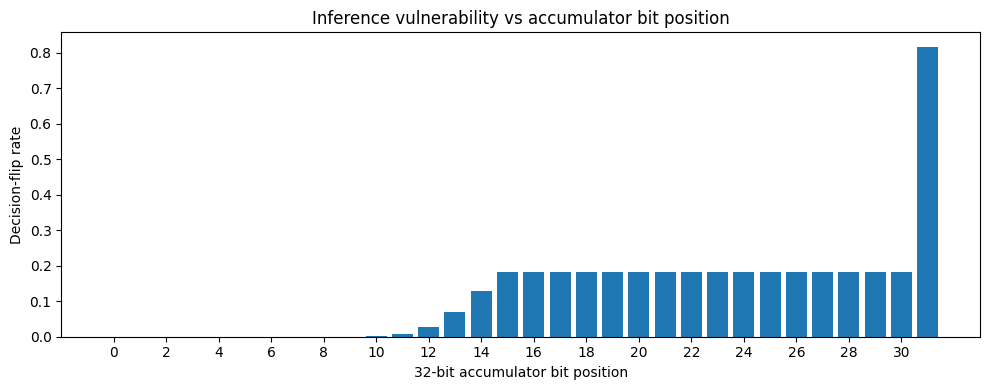

Saved: /content/tinyfault_artifacts/accumulator_bit_vulnerability.png


In [34]:

# Cell 35 — Primary result: vulnerability by accumulator bit

bit_summary = (
    fault_df.groupby("bit", as_index=False)
    .agg(
        injections=("decision_flip", "size"),
        decision_flips=("decision_flip", "sum"),
        flip_rate=("decision_flip", "mean"),
    )
)

display(bit_summary)

plt.figure(figsize=(10, 4))
plt.bar(bit_summary["bit"], bit_summary["flip_rate"])
plt.xlabel("32-bit accumulator bit position")
plt.ylabel("Decision-flip rate")
plt.title("Inference vulnerability vs accumulator bit position")
plt.xticks(np.arange(0, 32, 2))
plt.tight_layout()

bit_plot_path = ARTIFACT_DIR / "accumulator_bit_vulnerability.png"
plt.savefig(bit_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", bit_plot_path)


,count
Decision preserved,19615
Decision flip,2785


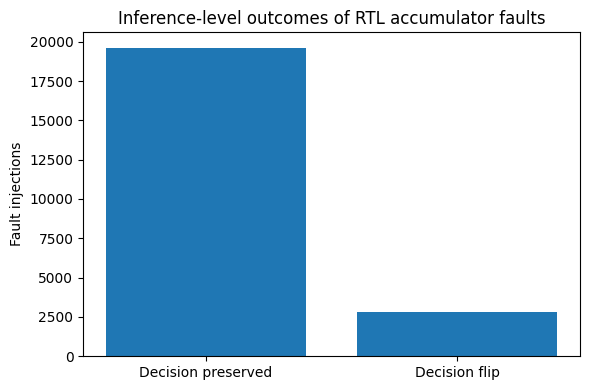

\nFive most vulnerable accumulator bits:


,bit,injections,decision_flips,flip_rate
0,31,700,572,0.817143
1,15,700,128,0.182857
2,28,700,128,0.182857
3,30,700,128,0.182857
4,25,700,128,0.182857


In [35]:

# Cell 36 — Outcome distribution and most vulnerable bits

outcome_counts = pd.Series({
    "Decision preserved": int((~fault_df["decision_flip"]).sum()),
    "Decision flip": int(fault_df["decision_flip"].sum()),
})

display(outcome_counts.to_frame("count"))

plt.figure(figsize=(6, 4))
plt.bar(outcome_counts.index, outcome_counts.values)
plt.ylabel("Fault injections")
plt.title("Inference-level outcomes of RTL accumulator faults")
plt.tight_layout()

outcome_plot_path = ARTIFACT_DIR / "fault_outcome_distribution.png"
plt.savefig(outcome_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("\\nFive most vulnerable accumulator bits:")
display(
    bit_summary.sort_values("flip_rate", ascending=False)
    .head(5)
    .reset_index(drop=True)
)


,neuron,injections,decision_flips,flip_rate,class_name
0,0,3200,285,0.089063,Angry
1,1,3200,131,0.040938,Disgust
2,2,3200,669,0.209063,Fear
3,3,3200,206,0.064375,Happy
4,4,3200,578,0.180625,Sad
5,5,3200,212,0.066250,Surprise
6,6,3200,704,0.220000,Neutral


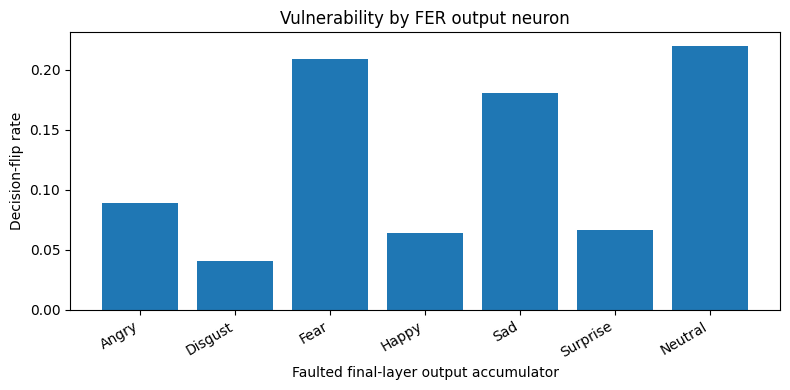

Saved: /content/tinyfault_artifacts/output_neuron_vulnerability.png


In [36]:

# Cell 37 — Vulnerability by output neuron

neuron_summary = (
    fault_df.groupby("neuron", as_index=False)
    .agg(
        injections=("decision_flip", "size"),
        decision_flips=("decision_flip", "sum"),
        flip_rate=("decision_flip", "mean"),
    )
)

neuron_summary["class_name"] = CLASS_NAMES[neuron_summary["neuron"].to_numpy()]
display(neuron_summary)

plt.figure(figsize=(8, 4))
plt.bar(neuron_summary["class_name"], neuron_summary["flip_rate"])
plt.ylabel("Decision-flip rate")
plt.xlabel("Faulted final-layer output accumulator")
plt.title("Vulnerability by FER output neuron")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

neuron_plot_path = ARTIFACT_DIR / "output_neuron_vulnerability.png"
plt.savefig(neuron_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", neuron_plot_path)


In [37]:

# Cell 38 — RTL-stage summary

rtl_summary = {
    "clean_fp32_test_accuracy": float(fp32_acc),
    "clean_int8_test_accuracy": float(int8_acc),
    "seed_samples": int(N_FAULT_SEEDS),
    "final_layer_features": int(N_FEATURES),
    "final_layer_classes": int(N_CLASSES),
    "rtl_fault_injections": int(len(fault_df)),
    "rtl_python_accumulator_bit_exact": bool(acc_exact),
    "accumulator_reconstruction_tflite_agreement": float(reconstruction_agreement),
    "overall_decision_flip_rate": float(fault_df["decision_flip"].mean()),
    "most_vulnerable_bit": int(
        bit_summary.loc[bit_summary["flip_rate"].idxmax(), "bit"]
    ),
    "most_vulnerable_bit_flip_rate": float(
        bit_summary["flip_rate"].max()
    ),
}

display(pd.Series(rtl_summary, name="value"))
print("\\nRAW RTL SUMMARY:")
print(rtl_summary)


,value
clean_fp32_test_accuracy,0.62449
clean_int8_test_accuracy,0.625417
seed_samples,100
final_layer_features,32
final_layer_classes,7
rtl_fault_injections,22400
rtl_python_accumulator_bit_exact,True
accumulator_reconstruction_tflite_agreement,1.0
overall_decision_flip_rate,0.12433
most_vulnerable_bit,31


\nRAW RTL SUMMARY:
{'clean_fp32_test_accuracy': 0.6244897842407227, 'clean_int8_test_accuracy': 0.625417439703154, 'seed_samples': 100, 'final_layer_features': 32, 'final_layer_classes': 7, 'rtl_fault_injections': 22400, 'rtl_python_accumulator_bit_exact': True, 'accumulator_reconstruction_tflite_agreement': 1.0, 'overall_decision_flip_rate': 0.12433035714285715, 'most_vulnerable_bit': 31, 'most_vulnerable_bit_flip_rate': 0.8171428571428572}


## Interpretation and scope

The frozen experiment demonstrates:

- a FER2013-derived CNN workload using the dataset mirror's provided splits;
- full-INT8 TFLite conversion;
- extraction of deployed final-layer integer tensors;
- signed INT8 × INT8 MAC arithmetic with a signed 32-bit accumulator;
- bit-exact agreement between the clean RTL accumulator and the Python integer reference;
- 22,400 deterministic single-bit accumulator fault scenarios;
- inference-aware analysis based on whether the reconstructed final-layer argmax changes.

### Scope limits

- Only the final fully connected classifier datapath is fault-tested; earlier CNN layers are not implemented in RTL.
- Each fault is injected into a **completed** output-neuron accumulator, not at arbitrary MAC cycles.
- The campaign uses 100 correctly classified INT8 test samples, so the reported flip rates describe this frozen campaign rather than a population-level hardware failure probability.
- Faulty accumulator values are mapped to reconstructed pre-output-requantization class scores using the per-output accumulator scales. Clean reconstructed decisions were verified against TFLite for the campaign samples; exact TFLite post-quantization behavior for every faulty accumulator was not separately emulated.
- Physical FPGA fault injection is outside the scope of this notebook.


In [38]:

# Cell 39 — Package generated project artifacts (dataset is NOT included)

# Copy RTL source/memory outputs into the artifact package.
rtl_export = ARTIFACT_DIR / "rtl"
rtl_export.mkdir(exist_ok=True)

for name in [
    "int8_mac_accum.sv",
    "tb_fault_campaign.sv",
    "weights.mem",
    "biases.mem",
    "activations.mem",
    "rtl_faults.csv",
]:
    src_file = RTL_DIR / name
    if src_file.exists():
        (rtl_export / name).write_bytes(src_file.read_bytes())

import json
(ARTIFACT_DIR / "rtl_summary.json").write_text(
    json.dumps(rtl_summary, indent=2)
)

import shutil
zip_base = "/content/tinyfault_fer_rtl_artifacts"
zip_path = shutil.make_archive(zip_base, "zip", ARTIFACT_DIR)

print("Final artifact ZIP:", zip_path)
print("Artifact directory:", ARTIFACT_DIR)


Final artifact ZIP: /content/tinyfault_fer_rtl_artifacts.zip
Artifact directory: /content/tinyfault_artifacts


In [39]:
from google.colab import files

files.download("/content/tinyfault_rtl/rtl_faults.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
from google.colab import files

files.download("/content/tinyfault_artifacts/accumulator_bit_vulnerability.png")
files.download("/content/tinyfault_artifacts/fault_outcome_distribution.png")
files.download("/content/tinyfault_artifacts/output_neuron_vulnerability.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>